# Ponto 2 · Evolução das regras do UnimNeuron-Safe

No ponto 1, comparámos o número de regras com e sem limite. Aqui acompanhamos cada regra individualmente para perceber se a contagem esconde criações, eliminações ou mudanças no que uma regra representa.

Usámos o mesmo `Sine_synth` do ponto 1, com seed 42 e `tau_merge=0.62`. Os dois testes de 5 000 observações usam os mesmos dados e diferem apenas no limite de regras.

## O que registámos e porquê

Cada regra recebe um ID sequencial na criação, que mantém até sair. Assim, uma mudança de posição na lista de regras preserva a identidade da regra. Numa fusão, a regra sobrevivente conserva o seu ID e o registo liga-o ao ID da regra absorvida.

| Registo | O que nos permite observar |
|---|---|
| Criação, remoção por limite e fusão | Quando cada regra aparece, sai ou é incorporada noutra. Uma candidata removida no próprio passo também fica registada. |
| Adaptação do antecedente | Como variam o centro, o sigma e o suporte estrutural da regra. O centro localiza a região que a regra representa e o sigma indica a sua largura. |
| Atualização do consequente e mudança de classe | Como evoluem as contagens ponderadas por classe, incluindo quando muda a classe com maior peso na regra. |
| Ativação na previsão | Quanto cada regra se ativa antes da atualização. A regra dominante é a de maior ativação positiva, com desempate pela ordem do modelo. |
| Tempo de vida e últimas ativações | Quando a regra nasceu e saiu, quantas vezes foi ativada ou dominante e quando isso aconteceu pela última vez. |

A subclasse chama os métodos originais. O registo lê a ativação já calculada pelo modelo e guarda os estados das regras durante a atualização. A classe dominante de uma regra é local. A previsão do modelo combina as contribuições de várias regras.

In [ ]:
import csv
import gzip
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

root = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "ENF_UnimNeuron_Safe.py").is_file())
results = root / "results" / "2_rule_evolution"
report = json.loads((results / "summary.json").read_text(encoding="utf-8"))

columns = {
    "create": "Criações",
    "evict": "Remoções por limite",
    "immediate_eviction": "Candidatas removidas de imediato",
    "merge": "Fusões",
    "adapt": "Adaptações do antecedente",
    "update_consequent": "Atualizações do consequente",
    "class_change": "Mudanças de classe da regra",
}
capped, uncapped = report["runs"]
lines = ["| Resultado | Limite de 5 | Sem limite |", "|---|---:|---:|"]
for event, label in columns.items():
    a, b = (run["events"].get(event, 0) for run in (capped, uncapped))
    lines.append(f"| {label} | {a:,} | {b:,} |".replace(",", " "))
lines.append(f'| Regras ativas no fim | {capped["final_rules"]} | {uncapped["final_rules"]} |')
display(Markdown("\n".join(lines)))

| Resultado | Limite de 5 | Sem limite |
|---|---:|---:|
| Criações | 4 409 | 73 |
| Remoções por limite | 4 404 | 0 |
| Candidatas removidas de imediato | 4 397 | 0 |
| Fusões | 0 | 0 |
| Adaptações do antecedente | 591 | 4 927 |
| Atualizações do consequente | 24 917 | 245 505 |
| Mudanças de classe da regra | 565 | 3 657 |
| Regras ativas no fim | 5 | 73 |

## O que os registos mostram

Com o limite, 4 397 das 4 404 remoções ocorreram no próprio passo de criação da candidata. Nas outras sete, saiu uma regra que já existia. Isto explica como a contagem pode ficar em cinco enquanto o modelo continua a propor regras e, por vezes, troca uma das que estavam ativas.

Sem limite, as 73 regras criadas ficaram ativas até ao fim. Houve 4 927 adaptações de antecedentes ao longo do teste. As atualizações dos consequentes contam alterações em regras individuais, pelo que uma observação pode contribuir com várias atualizações.

O `Sine_synth` usado aqui tem um conceito fixo. Os registos mostram a evolução das regras durante a aprendizagem deste stream e servirão para estudar a reação ao *concept drift* nos cenários controlados seguintes.

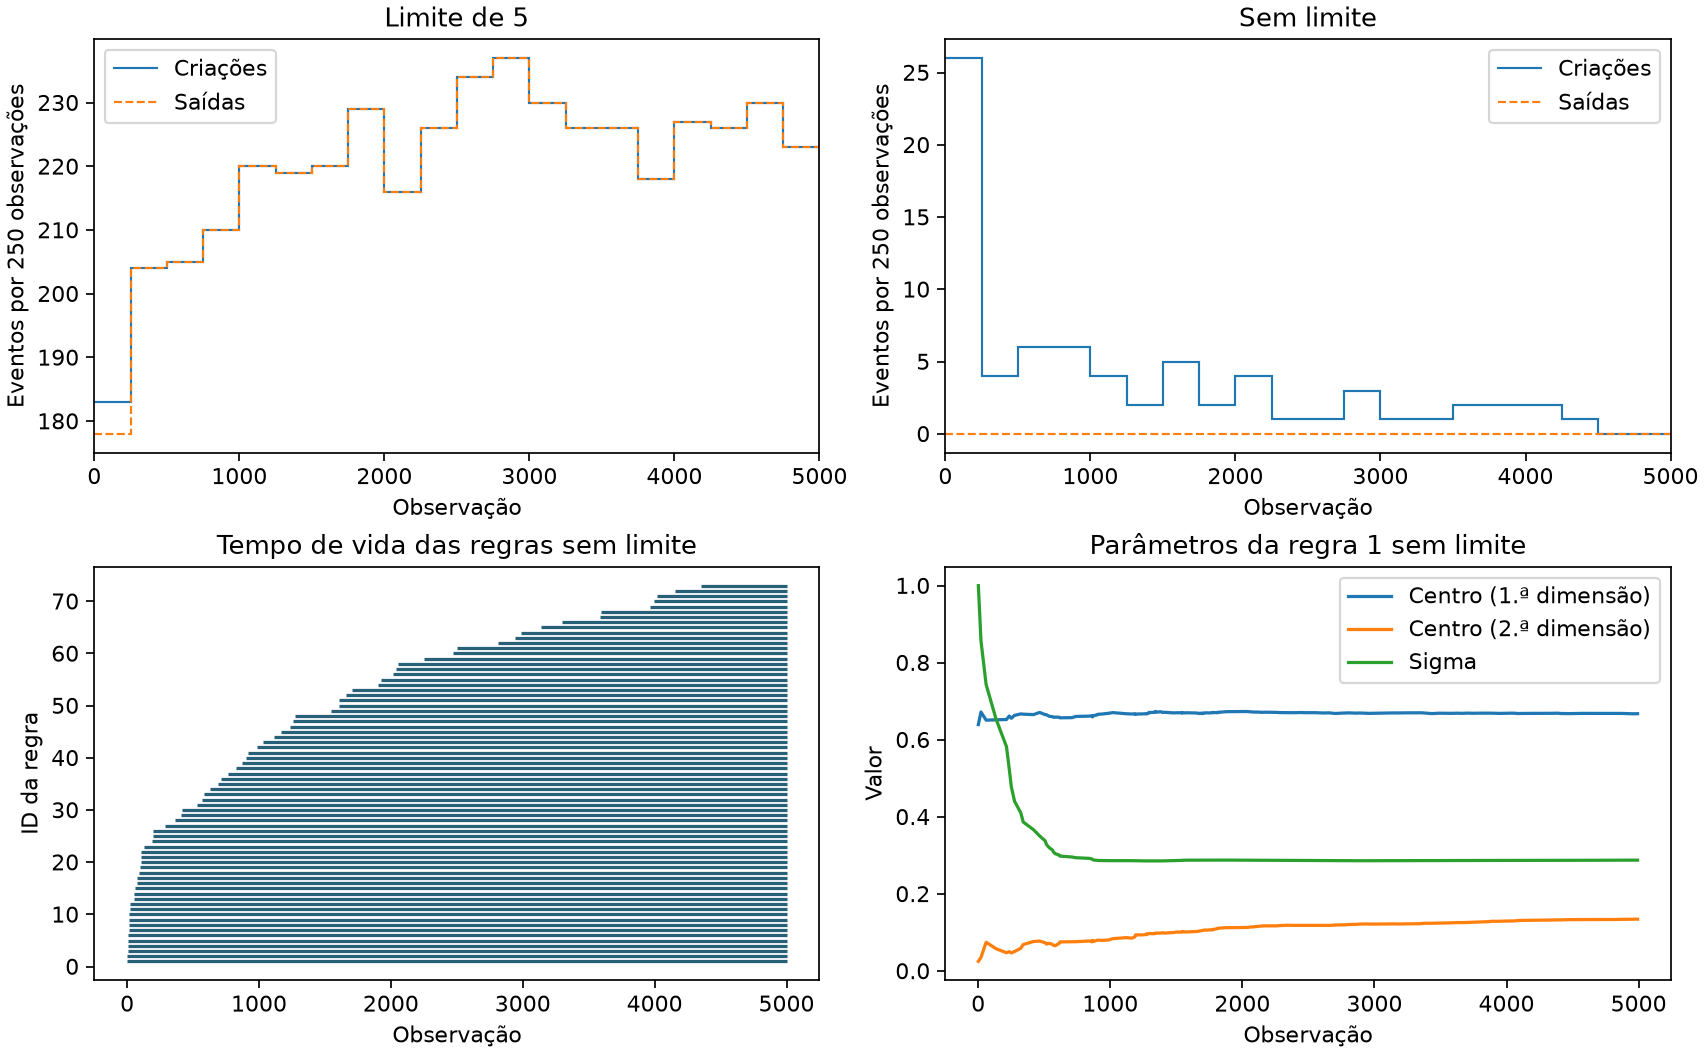

In [ ]:
display(Image(filename=str(results / "timeline.png")))

Os painéis de cima mostram criações e saídas por blocos de 250 observações. Os dois painéis usam escalas verticais diferentes. Em baixo, cada linha horizontal acompanha um ID no teste sem limite, desde a criação até à última observação. Na regra 1, o sigma desce de cerca de 1 para 0,29, enquanto a primeira coordenada do centro varia pouco. A região representada pela regra torna-se mais estreita ao longo do teste.

## Exemplo de uma substituição

Na sexta observação do teste com limite, o registo identifica a nova regra e a regra removida. A contagem continua em cinco, mas os IDs revelam a troca.

In [ ]:
with gzip.open(results / "capped_quick_events.csv.gz", "rt", encoding="utf-8", newline="") as file:
    example = [row for row in csv.DictReader(file)
               if row["sample"] == "6" and row["event"] in {"create", "evict"}]

event_labels = {"create": "Criação", "evict": "Remoção por limite"}
lines = ["| Observação | Evento | ID | Suporte |", "|---:|---|---:|---:|"]
for row in example:
    lines.append(f'| {row["sample"]} | {event_labels[row["event"]]} | '
                 f'{row["rule_id"]} | {row["support"]} |')
display(Markdown("\n".join(lines)))

| Observação | Evento | ID | Suporte |
|---:|---|---:|---:|
| 6 | Criação | 6 | 1 |
| 6 | Remoção por limite | 1 | 1 |

## Verificação contra o baseline

Em cada observação, comparámos a classe prevista e o número de regras após a atualização com os ficheiros do ponto 1. Os dois testes de 5 000 observações guardam os registos detalhados. A execução de 40 000 observações também tem o registo ativo e guarda as contagens agregadas.

As duas experiências curtas tiveram zero fusões. Exercitámos esse ramo num teste técnico separado, com condições de fusão relaxadas. Confirmámos a correspondência entre o ID sobrevivente e o ID absorvido em cada fusão e comparámos previsões e parâmetros das regras com o modelo original.

In [ ]:
runs = [("Limite de 5", capped), ("Sem limite", uncapped),
        ("Baseline completo com limite de 5", report["full_check"])]
lines = ["| Execução | Observações | Previsões e contagens coincidem |",
         "|---|---:|---|"]
for label, run in runs:
    samples = f'{run["samples"]:,}'.replace(",", " ")
    match = "Sim, em todas" if run["exact_match"] else "Não"
    lines.append(f"| {label} | {samples} | {match} |")
merges = report["technical_merge_check"]["merges"]
lines.extend(["", f"Teste técnico de fusão: **{merges} fusões verificadas**."])
display(Markdown("\n".join(lines)))

| Execução | Observações | Previsões e contagens coincidem |
|---|---:|---|
| Limite de 5 | 5 000 | Sim, em todas |
| Sem limite | 5 000 | Sim, em todas |
| Baseline completo com limite de 5 | 40 000 | Sim, em todas |

Teste técnico de fusão: **29 fusões verificadas**.

## Ficheiros e reprodução

Em `results/2_rule_evolution/`, os ficheiros `*_events.csv.gz` guardam os eventos com o estado da regra e `*_activations.csv.gz` guardam as ativações na previsão. Os ficheiros `*_lifetimes.csv` resumem o percurso de cada ID. Um campo de observação de saída vazio indica que a regra ainda estava ativa na última observação.

Para regenerar os ficheiros, seleciona o kernel da `.venv`, muda `repeat_experiment` para `True` e corre a célula seguinte. O script usa os CSV do ponto 1 para verificar a equivalência.

In [ ]:
import subprocess
import sys

repeat_experiment = False
if repeat_experiment:
    subprocess.run([sys.executable, str(root / "experiments" / "rule_evolution.py")],
                   cwd=root, check=True)